# Evaluation: all runs (EfficientNet + Perch 2.0)

* **main split**: 44 species, clip-level (recordings partly seen in training)
* **grouped split**: 34 species, by recording (test recordings never heard in training): the generalization test

Selection rule for the grouped-split EfficientNet experiments (fixed in advance): best mean **validation**
macro-F1 over seeds 42/43/44. Test numbers are reported, never used for choosing.
The 2025 row is copied from the 2025 report (leaky split, uncleaned data).

In [1]:
import sys
from pathlib import Path
ROOT = Path.cwd() if (Path.cwd() / "src").exists() else Path.cwd().parent
sys.path.insert(0, str(ROOT))
from src import config
import pandas as pd, numpy as np, matplotlib.pyplot as plt
E = config.EVAL_DIR

## 1. EfficientNet experiments on the grouped split (3 seeds each)

In [2]:
from src.EfficientNet.experiment import summarise
exp = summarise(); exp

,seeds,val_f1_macro,val_f1_std,val_acc,test_f1_macro,test_f1_std,test_acc,test_acc_std,best_epoch,minutes_per_seed
run,,,,,,,,,,
EfficientNet_05,3,0.364,0.012,0.480,0.484,0.017,0.658,0.006,9.667,15.933
EfficientNet_06,3,0.344,0.015,0.409,0.451,0.046,0.668,0.067,6.000,8.833
EfficientNet_03,3,0.296,0.014,0.401,0.423,0.037,0.577,0.048,1.333,6.367
EfficientNet_02b,3,0.251,0.029,0.370,0.447,0.039,0.626,0.074,1.667,4.633
EfficientNet_04,3,0.162,0.019,0.248,0.259,0.016,0.400,0.027,1.000,6.767


## 2. Final comparison (test set)

In [3]:
summ = pd.read_csv(E / "summary_metrics.csv").set_index("run")
probe = pd.read_csv(E / "perch_linear_probe.csv").set_index("run")
ex = pd.read_csv(E / "experiments.csv")
rows = [
    {"model": "EfficientNet 2025 (old split, leaky)", "split": "main", "accuracy": 0.947, "f1_macro": 0.91, "f1_std": np.nan},
    {"model": "EfficientNet_01 (2025 recipe)", "split": "main", "accuracy": summ.loc["EfficientNet_01", "accuracy"], "f1_macro": summ.loc["EfficientNet_01", "f1_macro"], "f1_std": np.nan},
    {"model": "Perch 2.0 + logistic regression", "split": "main", "accuracy": probe.loc["Perch2_LR_first_main", "accuracy"], "f1_macro": probe.loc["Perch2_LR_first_main", "f1_macro"], "f1_std": np.nan},
]
for run, label in [("EfficientNet_02b", "EfficientNet_02b (2025 recipe)"), ("EfficientNet_05", "EfficientNet_05 (best tuned)")]:
    g = ex[ex.run == run]
    rows.append({"model": label + ", 3 seeds", "split": "grouped", "accuracy": g.test_acc.mean(), "f1_macro": g.test_f1_macro.mean(), "f1_std": g.test_f1_macro.std()})
for kind in ["first", "mean"]:
    r = probe.loc[f"Perch2_LR_{kind}_grouped"]
    rows.append({"model": f"Perch 2.0 + logistic regression ({kind} window{'s' if kind == 'mean' else ''})", "split": "grouped",
                 "accuracy": r.accuracy, "f1_macro": r.f1_macro, "f1_std": np.nan})
final = pd.DataFrame(rows); final.to_csv(E / "final_comparison.csv", index=False)
final.round(3)

,model,split,accuracy,f1_macro,f1_std
0,"EfficientNet 2025 (old split, leaky)",main,0.947,0.910,NaN
1,EfficientNet_01 (2025 recipe),main,0.971,0.944,NaN
2,Perch 2.0 + logistic regression,main,0.941,0.924,NaN
3,"EfficientNet_02b (2025 recipe), 3 seeds",grouped,0.626,0.447,0.039
4,"EfficientNet_05 (best tuned), 3 seeds",grouped,0.658,0.484,0.017
5,Perch 2.0 + logistic regression (first window),grouped,0.722,0.543,NaN
6,Perch 2.0 + logistic regression (mean windows),grouped,0.724,0.568,NaN


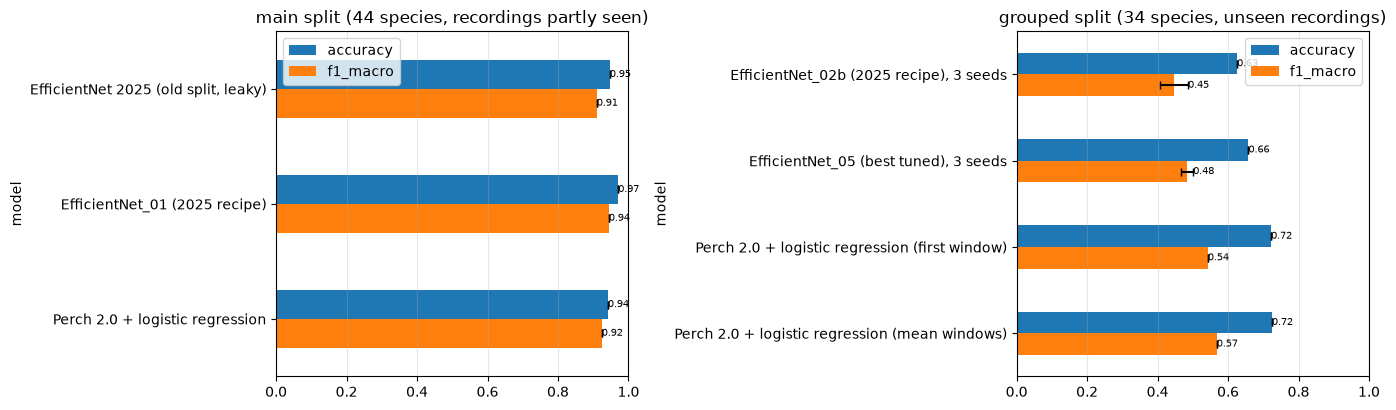

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.2))
for ax, split, title in zip(axes, ["main", "grouped"], ["main split (44 species, recordings partly seen)", "grouped split (34 species, unseen recordings)"]):
    d = final[final.split == split].set_index("model")
    d[["accuracy", "f1_macro"]].plot.barh(ax=ax, xerr=pd.DataFrame({"accuracy": 0, "f1_macro": d.f1_std.fillna(0)}).T.values, capsize=3)
    ax.set(xlim=(0, 1), title=title); ax.grid(axis="x", alpha=.3); ax.invert_yaxis()
    for c in ax.containers:
        if hasattr(c, "datavalues"): ax.bar_label(c, fmt="%.2f", fontsize=7)
plt.tight_layout(); plt.savefig(E / "final_comparison.png", dpi=150)

## 3. Per-class F1 on unseen recordings: Perch 2.0 vs best EfficientNet (mean of 3 seeds)

C:\Users\beno7\AppData\Local\Temp\ipykernel_15560\2687141365.py:2: Pandas4Warning: Starting with pandas version 4.0 all arguments of mean will be keyword-only.
  en = pd.concat([pd.read_csv(E / f"classification_report_EfficientNet_05_s{s}.csv", index_col=0).drop(index=drop)["f1-score"] for s in (42, 43, 44)], axis=1).mean(1)


Perch better on 18 of 34 species; F1 = 0 species: Perch 5 | EfficientNet_05 6


,Perch 2.0 + LR,EfficientNet_05,test clips
AtlanticSpottedDolphin,0.00,0.00,7
ClymeneDolphin,0.00,0.00,2
HarborPorpoise,0.00,0.00,2
GrayWhale,0.00,0.68,10
Narwhal,0.00,0.00,13
Fraser_sDolphin,0.06,0.00,39
MinkeWhale,0.22,0.32,7
RingedSeal,0.22,0.00,8
BottlenoseDolphin,0.23,0.26,26
Short_Finned(Pacific)PilotWhale,0.25,0.07,131


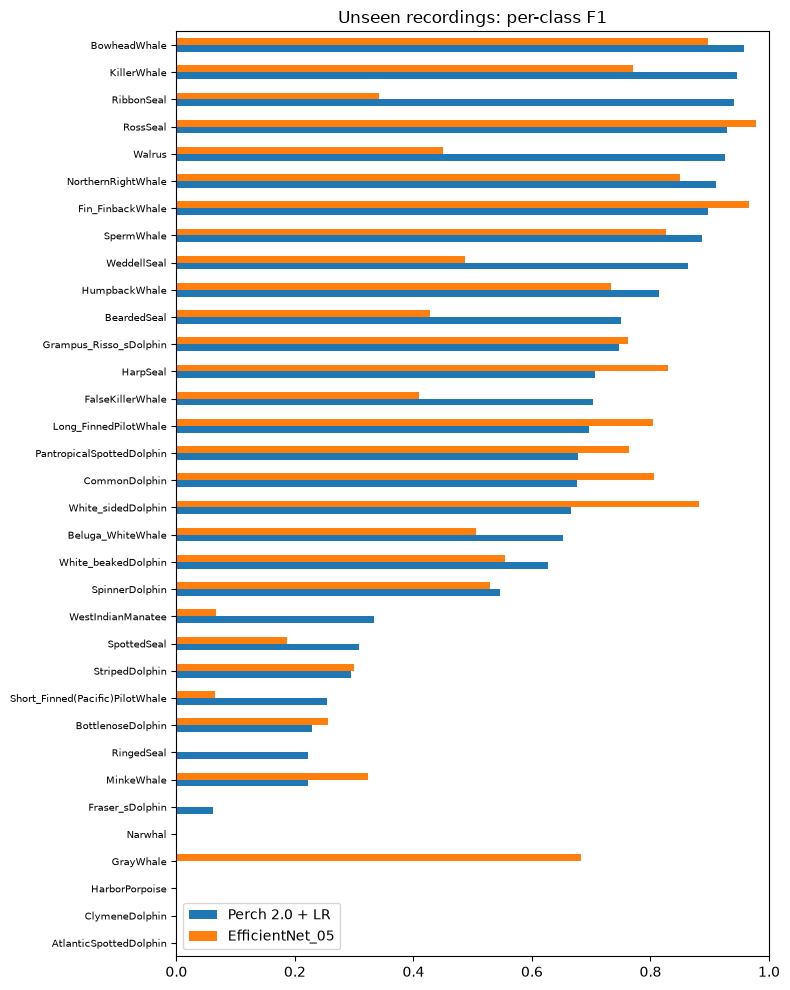

In [5]:
drop = ["accuracy", "macro avg", "weighted avg"]
en = pd.concat([pd.read_csv(E / f"classification_report_EfficientNet_05_s{s}.csv", index_col=0).drop(index=drop)["f1-score"] for s in (42, 43, 44)], axis=1).mean(1)
pe = pd.read_csv(E / "classification_report_Perch2_LR_first_grouped.csv", index_col=0).drop(index=drop)
pc = pd.DataFrame({"Perch 2.0 + LR": pe["f1-score"], "EfficientNet_05": en, "test clips": pe.support.astype(int)}).sort_values("Perch 2.0 + LR")
ax = pc.iloc[:, :2].plot.barh(figsize=(8, 10)); ax.set(xlim=(0, 1), title="Unseen recordings: per-class F1")
ax.tick_params(axis="y", labelsize=7); plt.tight_layout(); plt.savefig(E / "per_class_f1_perch_vs_effnet05.png", dpi=150)
print("Perch better on", int((pc.iloc[:, 0] > pc.iloc[:, 1]).sum()), "of", len(pc), "species;",
      "F1 = 0 species: Perch", int((pc.iloc[:, 0] == 0).sum()), "| EfficientNet_05", int((pc.iloc[:, 1] < 0.01).sum()))
pc.round(2)